![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

**This notebook is your report.** It is read on its own, by someone who has not seen notebooks 01 and 02, so it needs the prose as much as the code: the question, the final model, how good it is, where it fails, what drives it, and how far to trust it.

> **Done when:** someone who has never met your project can read this top to bottom and understand what you predicted, how well, compared with what, and where the model should not be used.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

|Item  |	Result |
--------|------------
| Dataset	| Comparative Political Data Set (CPDS) |
|Target |	Next-year unemployment rate|
|Training observations |	684|
|Test observations|	142|
|Training feature years|	2000–2018|
|Test feature years |	2019–2022|
|Selected model |	Tuned Ridge Regression|
|Ridge cross-validation MAE |	0.757|
|Persistence cross-validation MAE |	0.848|

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
import os
import joblib

from pathlib import Path
from dotenv import load_dotenv

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance



####

---
## 1. The question and the final model

The framing from notebook 01 and the choice from notebook 02, in a few sentences. Then refit the final pipeline on the whole training set.


This project investigates whether historical economic indicators and government political composition can be used to predict a country's unemployment rate one year ahead.

The model uses current unemployment, real GDP growth, inflation, and the shares of government cabinet posts held by left, centre, and right parties.

Three regression models were compared using chronological cross-validation: Linear Regression, Ridge Regression, and Random Forest.

Ridge Regression was selected because it achieved the lowest average cross-validation MAE (0.757 percentage points), slightly outperforming Linear Regression (0.758).

The model was trained using pre-pandemic observations and will now be evaluated on unemployment outcomes from 2020 to 2023.

The objective is to evaluate forecasting performance during a period of unusual economic disruption, not to estimate the causal impact of COVID-19.

---
## 2. Test once

The final model on the test set, **once**. Compare the score with the cross-validated estimate and with the baseline. If it is much worse than the estimate, say what that tells you.

In [2]:
load_dotenv()

data_path = os.getenv("DATA_PATH")
if not data_path:
    raise ValueError("DATA_PATH is not set")

df = pd.read_excel(data_path)

train, test, X_train, X_test, y_train, y_test = (
    prepare_unemployment_data(df)
)

print("Training:", X_train.shape)
print("Test:", X_test.shape)

Training: (684, 6)
Test: (142, 6)


In [3]:
model_path = Path("../models/ridge_unemployment.pkl")

final_model = joblib.load(model_path)

print(final_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unemployment', 'gdp_growth',
                                                   'inflation', 'gov_left',
                                                   'gov_centre',
                                                   'gov_right'])])),
                ('model', Ridge(alpha=1))])


In [4]:
y_pred = final_model.predict(X_test)

# Evaluation metrics
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

# Persistence baseline on exactly the same test rows
persistence_pred = X_test["unemployment"].to_numpy()

persistence_mae = mean_absolute_error(
    y_test, persistence_pred
)

# Dummy mean baseline using training targets only
dummy_pred = np.full(
    len(y_test),
    y_train.mean()
)

dummy_mae = mean_absolute_error(y_test, dummy_pred)

print(f"Ridge Test MAE:       {test_mae:.3f}")
print(f"Ridge Test RMSE:      {test_rmse:.3f}")
print(f"Ridge Test R²:        {test_r2:.3f}")
print(f"Persistence Test MAE: {persistence_mae:.3f}")
print(f"Dummy Test MAE:       {dummy_mae:.3f}")

Ridge Test MAE:       1.044
Ridge Test RMSE:      1.339
Ridge Test R²:        0.741
Persistence Test MAE: 0.768
Dummy Test MAE:       2.853


In [5]:
evaluation = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Persistence Baseline",
        "Dummy Mean Baseline"
    ],
    "Test MAE": [
        test_mae,
        persistence_mae,
        dummy_mae
    ]
})

evaluation.sort_values("Test MAE")

,Model,Test MAE
1,Persistence Baseline,0.768310
0,Ridge Regression,1.043524
2,Dummy Mean Baseline,2.852761


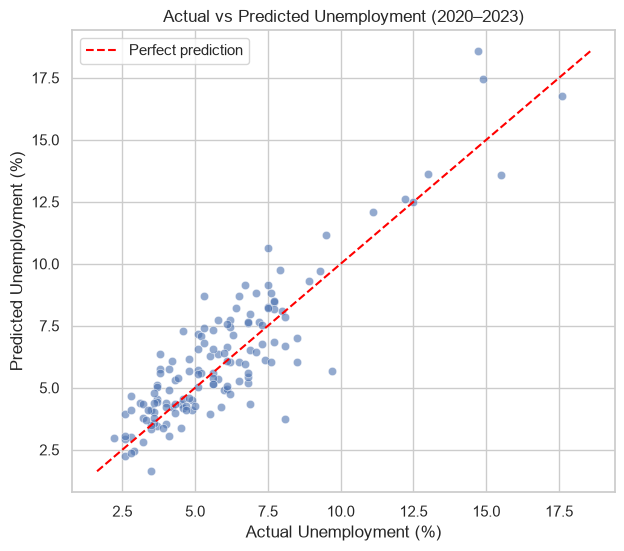

In [6]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Unemployment (%)")
plt.ylabel("Predicted Unemployment (%)")
plt.title("Actual vs Predicted Unemployment (2020–2023)")
plt.legend()
plt.show()

### Final Test Evaluation

The Ridge Regression model was evaluated on previously unseen unemployment outcomes from 2020 to 2023.

The model achieved a test MAE of 1.044 percentage points, RMSE of 1.339, and R² of 0.741.

Compared with its pre-pandemic cross-validation MAE of 0.757, the test MAE increased by approximately 38%, indicating weaker generalization to the test period.

The persistence baseline, which assumes next year's unemployment equals the current year's unemployment, achieved a lower test MAE of 0.768. The DummyRegressor baseline achieved a test MAE of 2.853.

Although Ridge substantially outperformed the dummy baseline, it did not outperform the persistence baseline on the final test data.

These results are consistent with the hypothesis that historical predictive relationships may be less reliable during periods of economic disruption. However, the results alone do not establish that the COVID-19 pandemic caused the performance deterioration.

### Why did Ridge performed worse than persistant baseline?

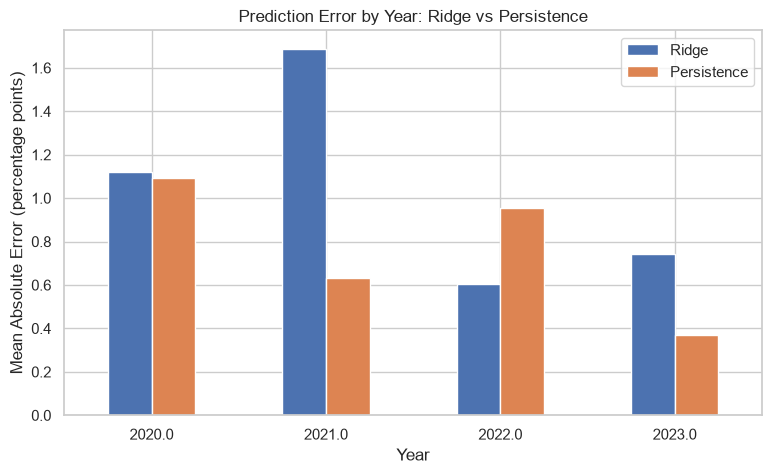

In [18]:
results = test[
    ["country", "year", "target_year"]
].copy()

results["actual"] = y_test.to_numpy()
results["ridge_pred"] = y_pred
results["persistence_pred"] = X_test["unemployment"].to_numpy()

results["ridge_error"] = (
    results["actual"] - results["ridge_pred"]
).abs()

results["persistence_error"] = (
    results["actual"] - results["persistence_pred"]
).abs()

yearly_mae = (
    results.groupby("target_year")[
        ["ridge_error", "persistence_error"]
    ]
    .mean()
)

yearly_mae.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Prediction Error by Year: Ridge vs Persistence")
plt.xlabel("Year")
plt.ylabel("Mean Absolute Error (percentage points)")
plt.xticks(rotation=0)
plt.legend(["Ridge", "Persistence"])
plt.show()

---
## 3. Where it goes wrong

Classification: the confusion matrix and the per-class results, at your chosen threshold. Regression: the residuals, and where they are largest. Look at a few of the worst predictions and say what they have in common.

In [7]:
results = test[
    ["country", "year", "target_year"]
].copy()

results["actual"] = y_test.to_numpy()
results["predicted"] = y_pred

results["residual"] = (
    results["actual"] - results["predicted"]
)

results["absolute_error"] = results["residual"].abs()

results.head()

,country,year,target_year,actual,predicted,residual,absolute_error
59,Australia,2019,2020.0,6.5,5.262294,1.237706,1.237706
60,Australia,2020,2021.0,5.1,7.185039,-2.085039,2.085039
61,Australia,2021,2022.0,3.7,4.549664,-0.849664,0.849664
123,Austria,2019,2020.0,6.0,4.927168,1.072832,1.072832
124,Austria,2020,2021.0,6.2,7.748800,-1.548800,1.548800


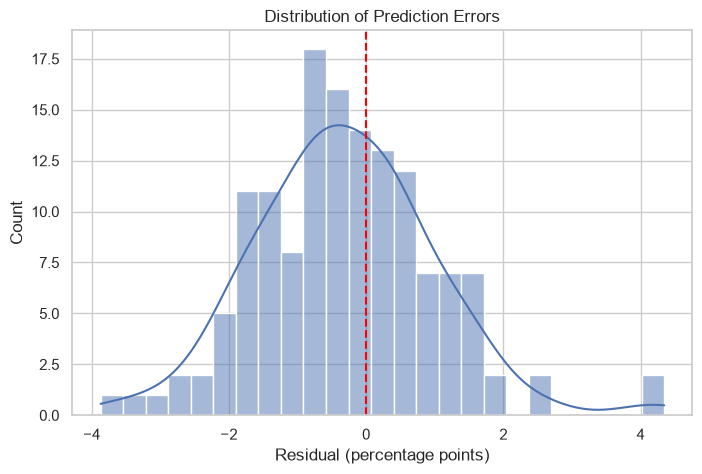

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=results,
    x="residual",
    bins=25,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual (percentage points)")
plt.ylabel("Count")
plt.show()

In [9]:
worst_predictions = results.sort_values(
    "absolute_error",
    ascending=False
).head(10)

worst_predictions[
    [
        "country",
        "target_year",
        "actual",
        "predicted",
        "residual",
        "absolute_error"
    ]
].round(2)

,country,target_year,actual,predicted,residual,absolute_error
1897,USA,2020.0,8.1,3.76,4.34,4.34
285,Canada,2020.0,9.7,5.67,4.03,4.03
744,Greece,2021.0,14.7,18.57,-3.87,3.87
1898,USA,2021.0,5.3,8.70,-3.40,3.40
286,Canada,2021.0,7.5,10.64,-3.14,3.14
1834,United Kingdom,2021.0,4.6,7.27,-2.67,2.67
1219,Malta,2021.0,3.8,6.38,-2.58,2.58
487,Estonia,2020.0,6.9,4.33,2.57,2.57
1642,Spain,2021.0,14.9,17.44,-2.54,2.54
1096,Lithuania,2020.0,8.5,6.03,2.47,2.47


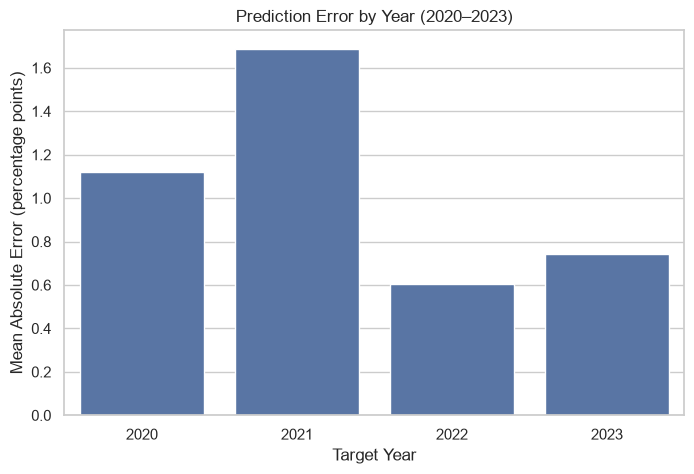

In [10]:
yearly_errors = (
    results.groupby("target_year")["absolute_error"]
    .mean()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=yearly_errors.index.astype(int),
    y=yearly_errors.values
)

plt.title("Prediction Error by Year (2020–2023)")
plt.xlabel("Target Year")
plt.ylabel("Mean Absolute Error (percentage points)")
plt.show()

---
## 4. What drives the predictions

Permutation importance on the test set, or an equivalent. Strongly related features share their importance, so read the ranking with care, and translate it into business terms.

In [11]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df

,Feature,Importance,Std
0,unemployment,1.650404,0.128623
1,gdp_growth,0.129449,0.046611
2,inflation,0.033681,0.025929
4,gov_centre,0.002278,0.003203
5,gov_right,0.001196,0.002837
3,gov_left,0.001149,0.006348


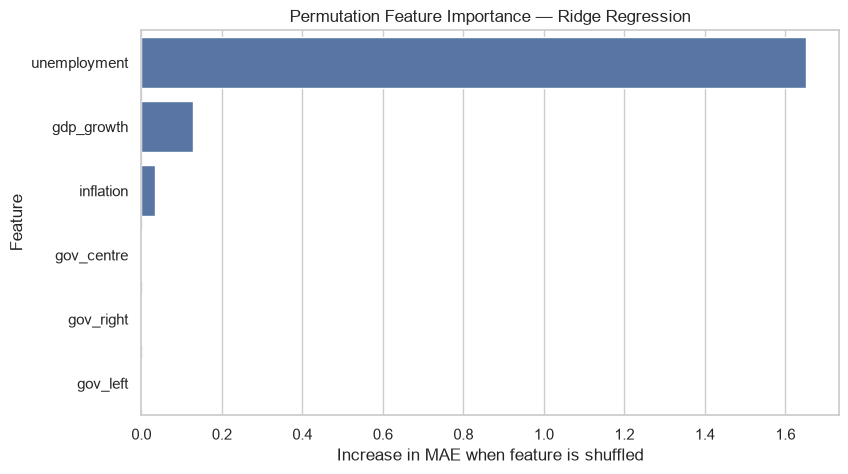

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance — Ridge Regression")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.ylabel("Feature")
plt.show()

### Feature Importance Interpretation

Permutation importance was used to investigate which input variables contribute most to the model's predictions.

The method measures how much prediction performance deteriorates when individual features are randomly shuffled.

Features producing a larger increase in prediction error are considered more important to the model.

However, correlated features can share predictive information, making individual importance estimates difficult to interpret.

Feature importance describes the model's predictive behavior and does not establish that an economic or political variable causes changes in unemployment.

---
## 5. Save, reload, predict

Save the fitted pipeline (and the threshold) with `joblib` into `models/`, reload it, and predict for a few new rows. This is your demo on Friday.

In [13]:
model_path = Path("../models/ridge_unemployment.pkl")

model_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(final_model, model_path)

print("Model saved:", model_path)

Model saved: ..\models\ridge_unemployment.pkl


In [14]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully")

Model loaded successfully


In [15]:
example_rows = X_test.head(3).copy()

demo_predictions = loaded_model.predict(
    example_rows
)

demo_results = example_rows.copy()
demo_results["predicted_next_year"] = demo_predictions

demo_results.round(2)

,unemployment,gdp_growth,inflation,gov_left,gov_centre,gov_right,predicted_next_year
59,5.2,1.80,1.61,0.0,0.0,100.0,5.26
60,6.5,-2.15,0.85,0.0,0.0,100.0,7.19
61,5.1,5.49,2.86,0.0,0.0,100.0,4.55


In [16]:
new_data = pd.DataFrame({
    "unemployment": [5.0, 8.0],
    "gdp_growth": [2.0, -1.0],
    "inflation": [2.0, 5.0],
    "gov_left": [50.0, 20.0],
    "gov_centre": [0.0, 30.0],
    "gov_right": [50.0, 50.0]
})

predictions = loaded_model.predict(new_data)

new_data["predicted_next_year"] = predictions

new_data.round(2)

,unemployment,gdp_growth,inflation,gov_left,gov_centre,gov_right,predicted_next_year
0,5.0,2.0,2.0,50.0,0.0,50.0,5.24
1,8.0,-1.0,5.0,20.0,30.0,50.0,8.87


### Model Deployment Demonstration

The final Ridge Regression pipeline was saved using `joblib` and successfully reloaded.

The saved pipeline includes both preprocessing and the trained regression model. It can therefore generate predictions from new observations containing the same six input features.

Three held-out observations were used to demonstrate the prediction process and compare predictions with known unemployment outcomes.

The model is suitable for educational and exploratory forecasting but is not recommended for high-stakes economic decision-making without further validation.

---
## 6. Conclusions and limitations

Would you use this model, and for what? Where should it not be trusted? What would you do with another week? Knowing the limits of your own model is part of the grade.

### Conclusions

This project investigated whether next-year unemployment could be predicted using historical unemployment, GDP growth, inflation, and government political composition.

Three model families were evaluated using chronological cross-validation.

Ridge Regression achieved the lowest average cross-validation MAE (0.757 percentage points), compared with 0.848 for the persistence baseline.

The selected model was evaluated on unemployment outcomes from 2020 to 2023 to examine whether relationships learned from pre-pandemic data generalized to a period of economic disruption.

**Final test findings:** To be completed after evaluating the held-out test data.

### Limitations

The analysis has several limitations:

- The dataset includes only 36 countries and a limited historical period.
- The dataset contains annual observations, which cannot capture rapid changes within a year.
- Predictions depend on current-year economic information being available.
- Important factors such as government emergency measures, labor market policies, and other economic shocks are not explicitly modeled.
- The model identifies predictive associations, not causal relationships.
- Performance during the pandemic may differ from performance under normal economic conditions.

### Possible Improvements

With additional time, I would investigate lagged economic variables, changes in unemployment rather than absolute unemployment levels, and additional labor market indicators.

I would also test the model on more recent economic data and examine whether country-specific characteristics improve forecasting performance.

The model could support exploratory economic forecasting, but it should not be used as the sole basis for high-stakes policy decisions.

In [17]:
print(f"Ridge Test MAE:       {test_mae:.3f}")
print(f"Ridge Test RMSE:      {test_rmse:.3f}")
print(f"Ridge Test R²:        {test_r2:.3f}")
print(f"Persistence Test MAE: {persistence_mae:.3f}")
print(f"Dummy Test MAE:       {dummy_mae:.3f}")

Ridge Test MAE:       1.044
Ridge Test RMSE:      1.339
Ridge Test R²:        0.741
Persistence Test MAE: 0.768
Dummy Test MAE:       2.853


## Work for slides:

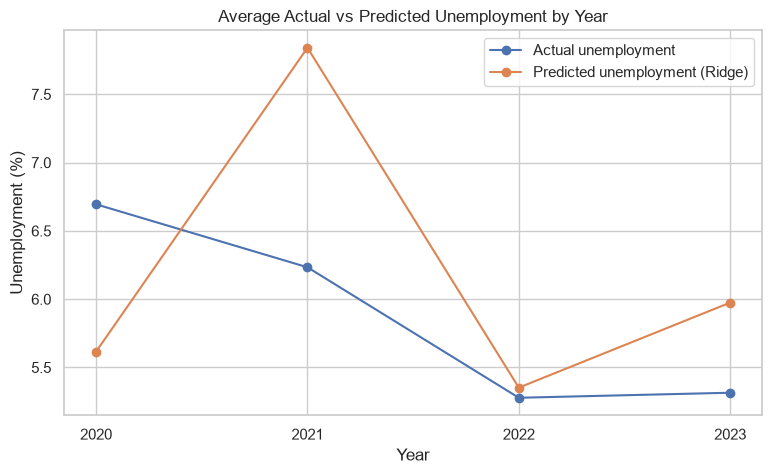

In [19]:
# Average actual and predicted unemployment by target year
yearly_predictions = (
    results.groupby("target_year")[["actual", "ridge_pred"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_predictions["target_year"],
    yearly_predictions["actual"],
    marker="o",
    label="Actual unemployment"
)

plt.plot(
    yearly_predictions["target_year"],
    yearly_predictions["ridge_pred"],
    marker="o",
    label="Predicted unemployment (Ridge)"
)

plt.title("Average Actual vs Predicted Unemployment by Year")
plt.xlabel("Year")
plt.ylabel("Unemployment (%)")
plt.xticks(yearly_predictions["target_year"])
plt.legend()
plt.show()

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

# Ridge is already trained and loaded
ridge_model = final_model

# Random Forest: replace parameters with your best
# parameters from Notebook 02 if they differ
forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['unemployment','gdp_growth','inflation','gov_left','gov_centre', 'gov_right']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concat

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, X_train.columns.tolist())
    ]
)

In [24]:
results = test[["country", "year", "target_year"]].copy()

results["Actual"] = y_test.to_numpy()

results["Ridge"] = ridge_model.predict(X_test)
results["Linear Regression"] = linear_model.predict(X_test)
results["Random Forest"] = forest_model.predict(X_test)

results["Persistence"] = X_test["unemployment"].to_numpy()

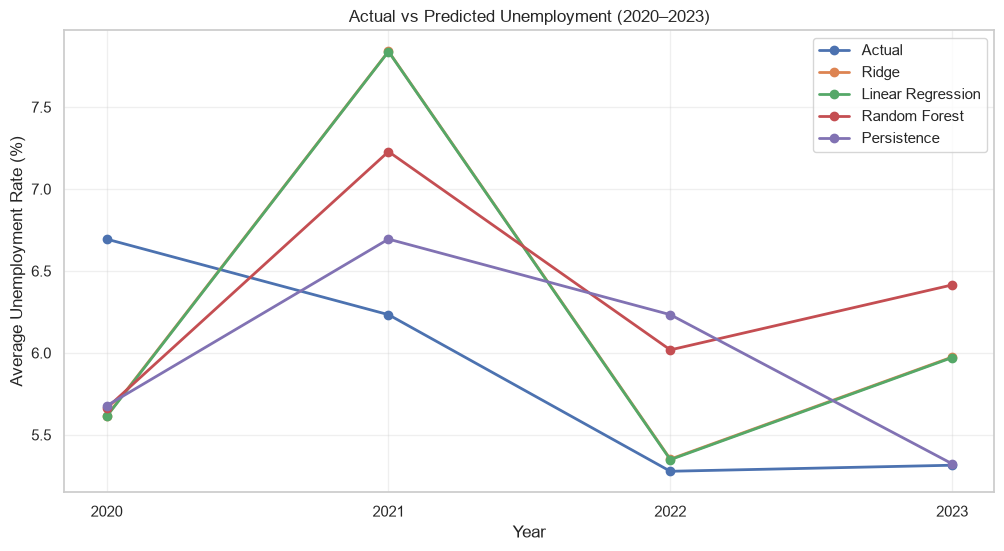

In [25]:
# Calculate average unemployment for each year
yearly_predictions = (
    results.groupby("target_year")[
        [
            "Actual",
            "Ridge",
            "Linear Regression",
            "Random Forest",
            "Persistence"
        ]
    ]
    .mean()
)

plt.figure(figsize=(12, 6))

for column in yearly_predictions.columns:
    plt.plot(
        yearly_predictions.index,
        yearly_predictions[column],
        marker="o",
        linewidth=2,
        label=column
    )

plt.title("Actual vs Predicted Unemployment (2020–2023)")
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(yearly_predictions.index.astype(int))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Actual vs Predicted Unemployment (2020–2023)

The comparison of actual and predicted average unemployment rates reveals differences in how the models responded to the pandemic period.

In 2020, all models underestimated average unemployment.

The largest discrepancy occurred in 2021, when Ridge Regression and Linear Regression predicted unemployment of approximately 7.8%, compared with an actual average of around 6.2%.

In 2022, the linear models produced predictions much closer to observed unemployment, while Random Forest and persistence predicted higher average rates.

In 2023, the persistence baseline closely followed the observed average unemployment rate.

Ridge and Linear Regression produced nearly identical predictions, suggesting that regularization had little effect on the model's behavior.

The findings indicate that relationships learned from pre-pandemic data did not generalize consistently across the test period, particularly in 2021.

However, yearly averages can conceal errors at the individual country level, so model performance must also be assessed using MAE and residual analysis.

In [26]:
from sklearn.metrics import mean_absolute_error

mae_comparison = pd.DataFrame({
    "Model": [
        "Ridge",
        "Linear Regression",
        "Random Forest",
        "Persistence"
    ],
    "Test MAE": [
        mean_absolute_error(results["Actual"], results["Ridge"]),
        mean_absolute_error(results["Actual"], results["Linear Regression"]),
        mean_absolute_error(results["Actual"], results["Random Forest"]),
        mean_absolute_error(results["Actual"], results["Persistence"])
    ]
})

mae_comparison.sort_values("Test MAE")

,Model,Test MAE
3,Persistence,0.768310
2,Random Forest,1.032349
0,Ridge,1.043524
1,Linear Regression,1.043823


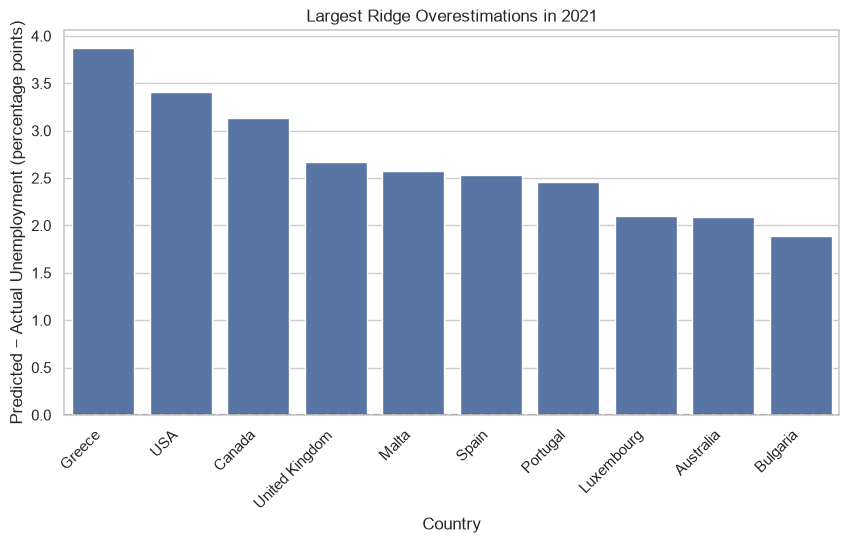

In [28]:
# Select predictions for 2021
results_2021 = results[
    results["target_year"] == 2021
].copy()

# Calculate signed prediction error
# Positive = model overestimated unemployment
# Negative = model underestimated unemployment
results_2021["error"] = (
    results_2021["Ridge"] - results_2021["Actual"]
)

# Find the 10 countries with the largest overestimations
top_countries = results_2021.nlargest(10, "error")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_countries,
    x="country",
    y="error"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Largest Ridge Overestimations in 2021")
plt.xlabel("Country")
plt.ylabel("Predicted − Actual Unemployment (percentage points)")
plt.xticks(rotation=45, ha="right")

plt.show()

### Country-Level Prediction Errors in 2021

The analysis of the largest Ridge Regression overestimations in 2021 reveals substantial differences between predicted and actual unemployment rates.

The largest overestimations occurred in Greece (approximately 3.9 percentage points), the USA (3.4), and Canada (3.1).

Other countries, including the United Kingdom, Malta, Spain, and Portugal, also experienced considerable overestimation.

These findings suggest that the model predicted higher unemployment than actually occurred in several countries during the pandemic recovery period.

One possible explanation is that economic relationships learned from pre-pandemic data did not fully capture the unusual conditions of 2020–2021, including changes in labor markets and government interventions.

However, these results are observational and cannot establish the causes of individual prediction errors.

Overall, the country-level analysis helps explain why Ridge Regression had its highest test-period MAE in 2021.

In [29]:
results_2021 = results[
    results["target_year"] == 2021
].copy()

results_2021["error"] = (
    results_2021["Ridge"] - results_2021["Actual"]
)

print("Mean signed error:", results_2021["error"].mean())

print(
    "Countries overestimated:",
    (results_2021["error"] > 0).sum()
)

print(
    "Countries underestimated:",
    (results_2021["error"] < 0).sum()
)

Mean signed error: 1.607287406077329
Countries overestimated: 35
Countries underestimated: 1


### Systematic Prediction Bias in 2021

Further analysis revealed a systematic upward prediction bias in Ridge Regression for 2021.

The model overestimated unemployment in 35 of 36 countries (97.2%) and underestimated unemployment in only one country.

The mean signed prediction error (predicted minus actual) was +1.61 percentage points.

This suggests that the model's poor performance in 2021 was not simply caused by isolated errors in a few countries. Instead, it systematically predicted higher unemployment than was observed across almost the entire dataset.

A possible explanation is that the relationships learned from pre-pandemic economic conditions did not generalize well to the unusual economic environment of 2020–2021.

These findings support the hypothesis that forecasting relationships became less reliable during this period, although they do not establish a causal effect of COVID-19.

In [30]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df.sort_values("Importance", ascending=False)

,Feature,Importance,Std
0,unemployment,1.650404,0.128623
1,gdp_growth,0.129449,0.046611
2,inflation,0.033681,0.025929
4,gov_centre,0.002278,0.003203
5,gov_right,0.001196,0.002837
3,gov_left,0.001149,0.006348


In [31]:
# Use the same random shuffle for all three political columns
# to keep their combinations together
rng = np.random.default_rng(42)

political_features = [
    "gov_left",
    "gov_centre",
    "gov_right"
]

X_shuffled = X_test.copy()

shuffle_order = rng.permutation(len(X_shuffled))

X_shuffled[political_features] = (
    X_test[political_features]
    .iloc[shuffle_order]
    .to_numpy()
)

# Compare MAE
original_mae = mean_absolute_error(
    y_test,
    final_model.predict(X_test)
)

shuffled_mae = mean_absolute_error(
    y_test,
    final_model.predict(X_shuffled)
)

print(f"Original MAE: {original_mae:.3f}")
print(f"Political features shuffled MAE: {shuffled_mae:.3f}")
print(f"Difference: {shuffled_mae - original_mae:.3f}")

Original MAE: 1.044
Political features shuffled MAE: 1.070
Difference: 0.026
